<a href="https://colab.research.google.com/github/IykeOdum/Real-Time-ASL-Recognition/blob/main/ASL_Recognition_Baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ASL Sign Recognition

Team: Iyke Odum, Ethan Frazier, Quinn Bankhead
Goal for milestone 3: Classify three ASL signs from hand landmarks extracted from WLASL videos. Notebook mainly used for experimenting.

The current experiment uses one representative frame per video, not a live webcam which will hopefully be implemented soon.


##Setup

Run the installation cell in Colab

In [1]:
%pip -q install mediapipe opencv-python-headless scikit-learn pandas matplotlib seaborn kagglehub tqdm joblib

In [2]:
from pathlib import Path
import json
import urllib.request

import cv2
import joblib
import kagglehub
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

# Change these to see what happens to accuracy
RANDOM_SEED = 42
NUM_SIGNS = 3
MIN_VIDEOS_PER_SIGN = 12
MAX_VIDEOS_PER_SIGN = 25
TEST_SIZE = 0.25
K_VALUES = range(1, 11)  # Candidate neighbor counts for cross validation
CV_FOLDS = 4  # Four stratified splits of the training set
SAMPLE_POSITIONS = (0.4, 0.5, 0.6)  # Relative positions in each video
OUTPUT_DIR = Path('/content/asl_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('MediaPipe version:', mp.__version__)
print('Output folder:', OUTPUT_DIR)

MediaPipe version: 1.2.3
Output folder: /content/asl_outputs


## Load the WLASL video dataset:

Just loads in the data and builds a video table for validation

In [3]:
DATASET_NAME = 'waseemnagahhenes/sign-language-dataset-wlasl-videos'
dataset_dir = Path(kagglehub.dataset_download(DATASET_NAME))

video_files = sorted(
    path for path in dataset_dir.rglob('*')
    if path.suffix.lower() in {'.mp4', '.avi', '.mov', '.mkv'}
)
json_files = sorted(dataset_dir.rglob('*.json'))

print('Dataset location:', dataset_dir)
print('Video files:', len(video_files))
print('JSON files:', len(json_files))
print('Example video paths:', [str(p.relative_to(dataset_dir)) for p in video_files[:3]])

if not video_files:
    raise ValueError('No videos found. Check the Kaggle download and folder structure.')

100%|██████████| 4.90G/4.90G [00:57<00:00, 91.9MB/s]

Extracting files...


Dataset location: /root/.cache/kagglehub/datasets/waseemnagahhenes/sign-language-dataset-wlasl-videos/versions/1
Video files: 12505
JSON files: 0
Example video paths: ['dataset/SL/a/01610.mp4', 'dataset/SL/a/01611.mp4', 'dataset/SL/a/01612.mp4']


In [15]:
def build_video_table(video_files, json_files):
    # return one row per video: ID, label, path, and optional metadata.
    annotation_file = next(
        (p for p in json_files if 'wlasl' in p.name.lower()), None
    )
    rows = []

    if annotation_file:
        with annotation_file.open(encoding='utf-8') as file:
            annotations = json.load(file)

        # Match an annotation's video_id to its video filename.
        videos_by_id = {path.stem: path for path in video_files}
        for sign in annotations:
            for instance in sign['instances']:
                video_id = str(instance['video_id'])
                if video_id not in videos_by_id:
                    continue
                rows.append({
                    'video_id': video_id,
                    'label': sign['gloss'],
                    'path': str(videos_by_id[video_id]),
                    'signer_id': instance.get('signer_id'),
                    'split': instance.get('split'),
                })
    else:
        # This Kaggle copy has one folder per sign and no signer metadata.
        for path in video_files:
            rows.append({
                'video_id': path.stem,
                'label': path.parent.name,
                'path': str(path),
                'signer_id': None,
                'split': None,
            })

    table = pd.DataFrame(rows)
    if table.empty:
        raise ValueError('No labeled videos found. Inspect the dataset layout.')
    return table.drop_duplicates(subset='path').reset_index(drop=True)

videos_df = build_video_table(video_files, json_files)
sign_counts = videos_df['label'].value_counts()

print('Labeled videos:', len(videos_df))
print('Unique signs:', videos_df['label'].nunique())
display(sign_counts.head(15).rename('video_count').to_frame())

Labeled videos: 12505
Unique signs: 2000


,video_count
label,
cousin,17
thin,16
before,16
cool,16
go,15
drink,15
computer,14
help,14
who,14


##Select a small balanced subset

Uses the three signs with the most videos given they have at least 12 vids. Also samples the same number of videos per sign, so a common sign does not dominate the training set. With the current Kaggle copy, the selected signs were cousin, thin, and before (16 each). If the source changes, the selection can change too.

In [5]:
eligible_counts = sign_counts[sign_counts >= MIN_VIDEOS_PER_SIGN]
if len(eligible_counts) < NUM_SIGNS:
    raise ValueError('Too few eligible signs. Lower MIN_VIDEOS_PER_SIGN.')

selected_signs = eligible_counts.head(NUM_SIGNS).index.tolist()
per_sign = min(MAX_VIDEOS_PER_SIGN, int(eligible_counts.loc[selected_signs].min()))

# Each group is sampled separately, so the number per label is equal.
selected_df = (
    videos_df[videos_df['label'].isin(selected_signs)]
    .groupby('label', group_keys=False)
    .sample(n=per_sign, random_state=RANDOM_SEED)
    .reset_index(drop=True)
)

print('Selected signs:', selected_signs)
print('Videos per sign:', per_sign)
display(selected_df['label'].value_counts().rename('videos').to_frame())

Selected signs: ['cousin', 'thin', 'before']
Videos per sign: 16


,videos
label,
before,16
cousin,16
thin,16


##Extract hand landmarks with MediaPipe (heavily relied on AI for this part idk how to do this lol)

MediaPipe detects **21 points per hand**. Each point has an `(x, y, z)` coordinate, giving **126 features** when representing up to two hands (`2 × 21 × 3`).

For each video, we inspect frames around **40%, 50%, and 60%** of its length and use the frame with the most detected hands. To reduce differences in position and scale, we subtract the wrist location and divide by the maximum wrist-to-landmark distance in the image plane. If only one hand is found, the missing hand is filled with zeros. Videos with no detected hands are skipped.

**Limitations:** This discards hand movement and much of the facial/body information important to ASL. The vector slots follow image left-to-right positions, not permanent left/right-hand identities. Two hands may be inconsistent across videos, so this is strictly a first baseline.

In [6]:
MODEL_URL = (
    'https://storage.googleapis.com/mediapipe-models/'
    'hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task'
)
MODEL_PATH = Path('/content/hand_landmarker.task')
if not MODEL_PATH.exists():
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)

options = mp.tasks.vision.HandLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(model_asset_path=str(MODEL_PATH)),
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_hands=2,
    min_hand_detection_confidence=0.4,
)
landmarker = mp.tasks.vision.HandLandmarker.create_from_options(options)
print('Hand Landmarker ready.')

Hand Landmarker ready.


In [16]:
def normalize_hand(hand_landmarks):
    # Convert 21 landmarks into a wrist-relative, scale-normalized (21, 3) array.
    points = np.array(
        [[point.x, point.y, point.z] for point in hand_landmarks],
        dtype=np.float32,
    )
    points -= points[0]  # The wrist becomes (0, 0, 0).
    scale = np.linalg.norm(points[:, :2], axis=1).max()
    return points / max(float(scale), 1e-6)  # Avoid division by zero.


def extract_hand_features(video_path, detector):
    # Return 126 landmark features from a video, or None if hands aren't found.
    video = cv2.VideoCapture(str(video_path))
    if not video.isOpened():
        return None

    try:
        frame_count = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
        if frame_count <= 0:
            return None

        best_hands = []
        for position in SAMPLE_POSITIONS:
            frame_number = int((frame_count - 1) * position)
            video.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
            success, frame = video.read()
            if not success:
                continue

            rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=np.ascontiguousarray(rgb_frame),
            )
            hands_found = detector.detect(image).hand_landmarks

            # Prefer a two-hand frame; otherwise keep the first one-hand frame.
            if len(hands_found) > len(best_hands):
                best_hands = hands_found
            if len(best_hands) == 2:
                break
    finally:
        video.release()  # Always close the video, even on early return.

    if not best_hands:
        return None

    # Sort before normalization: wrist x becomes zero after normalization.
    best_hands = sorted(best_hands, key=lambda hand: hand[0].x)
    hand_arrays = [normalize_hand(hand) for hand in best_hands]
    while len(hand_arrays) < 2:
        hand_arrays.append(np.zeros((21, 3), dtype=np.float32))

    return np.concatenate(hand_arrays).flatten()  # Shape: (126,)


# Check one video before running extraction on all selected videos.
test_video = selected_df.iloc[0]['path']
test_features = extract_hand_features(test_video, landmarker)
print('Test video:', Path(test_video).name)
print('Hand landmarks found:', test_features is not None)
print('Feature length:', len(test_features) if test_features is not None else 0)

Test video: 05727.mp4
Hand landmarks found: True
Feature length: 126


### Extract the selected videos

Preprocessing so one video becomes one row, so the train/test split will not accidentally place frames from the same video into both groups. Failed videos will be saved so the model wont iuse those.

In [17]:
feature_rows = []
failed_video_ids = []

for record in tqdm(selected_df.itertuples(index=False), total=len(selected_df)):
    values = extract_hand_features(record.path, landmarker)
    if values is None:
        failed_video_ids.append(record.video_id)
        continue

    row = {
        'video_id': record.video_id,
        'label': record.label,
        'signer_id': record.signer_id,
        'split': record.split,
    }
    row.update({f'feature_{i}': float(value) for i, value in enumerate(values)})
    feature_rows.append(row)

landmarks_df = pd.DataFrame(feature_rows)
if landmarks_df.empty:
    raise ValueError('No hand landmarks detected. Check the video paths and model.')

print('Usable videos:', len(landmarks_df))
print('Videos with no detected hands:', len(failed_video_ids))
print('Samples per sign:')
display(landmarks_df['label'].value_counts().to_frame('samples'))

# outputs saved landmarks for future runs
landmarks_path = OUTPUT_DIR / 'asl_landmarks.csv'
landmarks_df.to_csv(landmarks_path, index=False)
print('Saved:', landmarks_path)

  0%|          | 0/48 [00:00<?, ?it/s]

Usable videos: 48
Videos with no detected hands: 0
Samples per sign:


,samples
label,
before,16
cousin,16
thin,16


Saved: /content/asl_outputs/asl_landmarks.csv


##Choose K and evaluate the KNN baseline

Uses a StandardScaler + KNN. The scaler is fitted inside each training fold, preventing validation data from influencing its parameters.

1. Split the 48 videos into a 75% training subset and a 25% test subset.
2. Compare K=1 through K=10 using stratified four fold cross validation on the training subset only.
3. Choose the K with the highest average validation accuracy (breaking ties in favor of the smaller K).
4. Fit the selected model on all training samples, then evaluate on the test videos that weren't in training.

Note: not actually how the thing will work since we will use webcam later but for now this is good I guess and a future independent test set or unseen signers is needed for an unbiased final estimate since the model will just train from videos and it might use like lighting and video landmarks to predict.

In [18]:
feature_columns = [f'feature_{i}' for i in range(126)]
X = landmarks_df[feature_columns]
y = landmarks_df['label']

if X.isna().any().any():
    raise ValueError('Missing feature values found; inspect extraction results.')
if y.value_counts().min() < 2:
    raise ValueError('Each sign needs at least two usable videos for splitting.')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y
)

print('Train/test sizes:', len(X_train), '/', len(X_test))
print('Training labels:', y_train.value_counts().to_dict())
print('Testing labels:', y_test.value_counts().to_dict())

Train/test sizes: 36 / 12
Training labels: {'cousin': 12, 'thin': 12, 'before': 12}
Testing labels: {'cousin': 4, 'before': 4, 'thin': 4}


### Compare K values using training only cross validation

Each row below shows the mean accuracy from four validation folds. The test set remains unused while choosing K. The plotted error bars show one standard deviation across folds, not a confidence interval.

Best K from training-only cross-validation: 1


,k,mean_accuracy,std_accuracy
0,1,0.778,0.136
1,2,0.583,0.144
2,3,0.639,0.164
3,4,0.611,0.124
4,5,0.611,0.124
5,6,0.556,0.079
6,7,0.528,0.092
7,8,0.444,0.111
8,9,0.444,0.079
9,10,0.389,0.056


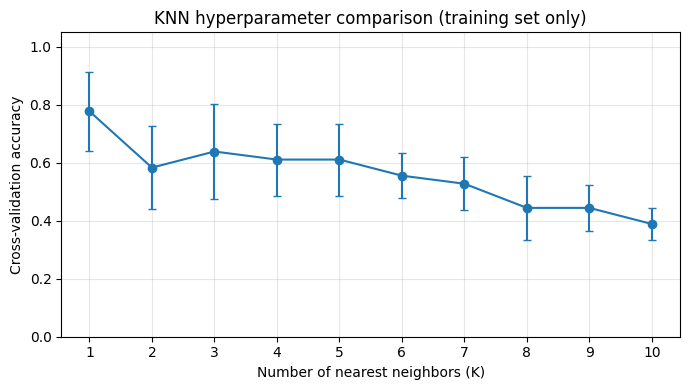

In [19]:
# Compare neighbor counts using only the training data.
# A fresh scaler is fitted for each CV fold within the pipeline.
min_fold_train_size = len(X_train) - int(np.ceil(len(X_train) / CV_FOLDS))
if max(K_VALUES) > min_fold_train_size:
    raise ValueError(
        f'Largest K ({max(K_VALUES)}) exceeds the smallest CV training fold '
        f'({min_fold_train_size}). Reduce the K range or CV_FOLDS.'
    )

cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_SEED,
)

cv_rows = []
for k in K_VALUES:
    candidate = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k),
    )
    fold_scores = cross_val_score(
        candidate, X_train, y_train,
        cv=cv, scoring='accuracy',
    )
    cv_rows.append({
        'k': k,
        'mean_accuracy': fold_scores.mean(),
        'std_accuracy': fold_scores.std(),
    })

cv_results_df = pd.DataFrame(cv_rows)
# Results are already ordered by increasing K, so idxmax prefers the
# smallest K if two candidates tie in mean accuracy.
best_k = int(cv_results_df.loc[cv_results_df['mean_accuracy'].idxmax(), 'k'])

print(f'Best K from training-only cross-validation: {best_k}')
display(cv_results_df.round(3))

plt.figure(figsize=(7, 4))
plt.errorbar(
    cv_results_df['k'], cv_results_df['mean_accuracy'],
    yerr=cv_results_df['std_accuracy'], fmt='o-', capsize=3,
)
plt.xticks(list(K_VALUES))
plt.ylim(0, 1.05)
plt.xlabel('Number of nearest neighbors (K)')
plt.ylabel('Cross-validation accuracy')
plt.title('KNN hyperparameter comparison (training set only)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'asl_knn_cross_validation.png', dpi=200)
plt.show()

In [20]:
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=best_k),
)
knn_model.fit(X_train, y_train)
y_pred = knn_model.predict(X_test)

predictions_df = pd.DataFrame({
    'video_id': landmarks_df.loc[X_test.index, 'video_id'].values,
    'actual_sign': y_test.to_numpy(),
    'predicted_sign': y_pred,
})
predictions_df['correct'] = (
    predictions_df['actual_sign'] == predictions_df['predicted_sign']
)
print(f'KNN trained using cross-validated K={best_k}')
display(predictions_df)

KNN trained using cross-validated K=1


,video_id,actual_sign,predicted_sign,correct
0,65415,cousin,cousin,True
1,05750,before,before,True
2,57943,thin,thin,True
3,05731,before,before,True
4,57953,thin,thin,True
5,13638,cousin,cousin,True
6,13648,cousin,cousin,True
7,13640,cousin,cousin,True
8,05739,before,before,True
9,57936,thin,thin,True


### Metrics and confusion matrix

Accuracy is the share of correct predictions. Precision, recall, and F1 give a more detailed result for each sign. On the confusion matrix, the rows are actual signs and columns are predictions; the diagonal contains correct predictions.

Test accuracy: 100.00% (12/12)
Macro F1-score: 1.00


,precision,recall,f1-score,support
before,1.0,1.0,1.0,4.0
cousin,1.0,1.0,1.0,4.0
thin,1.0,1.0,1.0,4.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,12.0
weighted avg,1.0,1.0,1.0,12.0


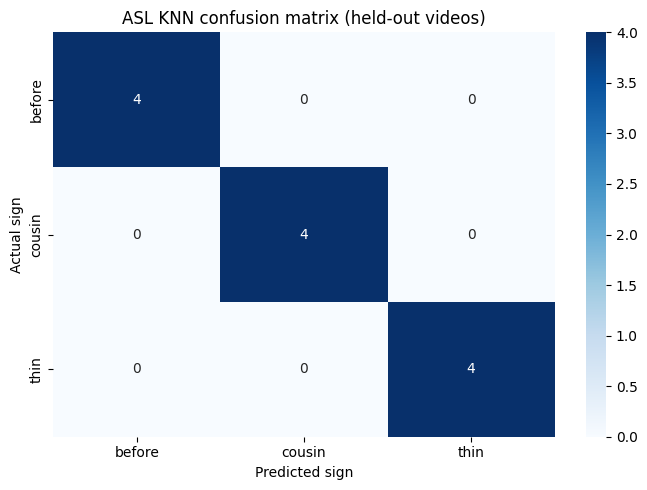

In [21]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, zero_division=0, output_dict=True)
report_df = pd.DataFrame(report).T

print(f'Test accuracy: {accuracy:.2%} ({predictions_df.correct.sum()}/{len(predictions_df)})')
print(f'Macro F1-score: {report["macro avg"]["f1-score"]:.2f}')
display(report_df.round(2))

classes = sorted(y.unique())
matrix = confusion_matrix(y_test, y_pred, labels=classes)
plt.figure(figsize=(7, 5))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.title('ASL KNN confusion matrix (held-out videos)')
plt.xlabel('Predicted sign')
plt.ylabel('Actual sign')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'asl_confusion_matrix.png', dpi=200)
plt.show()

##Save results

This exports the final fitted StandardScaler + KNN model, per-video test predictions, metrics, the confusion matrix, and cross-validation results and graph. The CSV from landmark extraction can be reused without processing the videos again.

NOTE: Don't need to run but it will also give a .pkl which we can use when we do integrate webcam

In [13]:
joblib.dump(knn_model, OUTPUT_DIR / 'asl_knn_model.pkl')
report_df.to_csv(OUTPUT_DIR / 'asl_evaluation_results.csv')
predictions_df.to_csv(OUTPUT_DIR / 'asl_test_predictions.csv', index=False)
cv_results_df.to_csv(OUTPUT_DIR / 'asl_knn_cross_validation.csv', index=False)

# Save project settings for teammates who will use the model later.
settings = {
    'dataset': DATASET_NAME,
    'selected_signs': selected_signs,
    'sample_positions': SAMPLE_POSITIONS,
    'random_seed': RANDOM_SEED,
    'test_size': TEST_SIZE,
    'k_neighbors': best_k,
    'k_candidates': list(K_VALUES),
    'cv_folds': CV_FOLDS,
    'cv_mean_accuracy_best_k': float(cv_results_df.loc[cv_results_df['k'] == best_k, 'mean_accuracy'].iloc[0]),
    'feature_count': len(feature_columns),
    'feature_method': 'wrist-relative, x/y-scaled, up to 2 hands, one sampled frame',
    'note': 'video-held-out evaluation only; signer identities unavailable',
}
with (OUTPUT_DIR / 'experiment_settings.json').open('w') as file:
    json.dump(settings, file, indent=2)

print('Saved project files:')
for file in sorted(OUTPUT_DIR.iterdir()):
    print('-', file.name)

Saved project files:
- asl_confusion_matrix.png
- asl_evaluation_results.csv
- asl_knn_cross_validation.csv
- asl_knn_cross_validation.png
- asl_knn_model.pkl
- asl_landmarks.csv
- asl_test_predictions.csv
- experiment_settings.json


In [14]:
# Optional: download all output files in one ZIP
from google.colab import files
import shutil

archive = shutil.make_archive('/content/asl_baseline_results', 'zip', OUTPUT_DIR)
files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>